<a href="https://colab.research.google.com/github/dilaraymercann/ml-supervised-learning/blob/main/01_titanic_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import pandas as pd
import seaborn as sns

df = sns.load_dataset("titanic")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [13]:
#Veriyi tanıma
print("Satır, sütun sayısı:", df.shape)
df.info()

Satır, sütun sayısı: (891, 15)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [14]:
#Eksik değerleri sayma
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


In [15]:
#Genel hayatta kalma oranı
df["survived"].value_counts()

,count
survived,
0,549
1,342


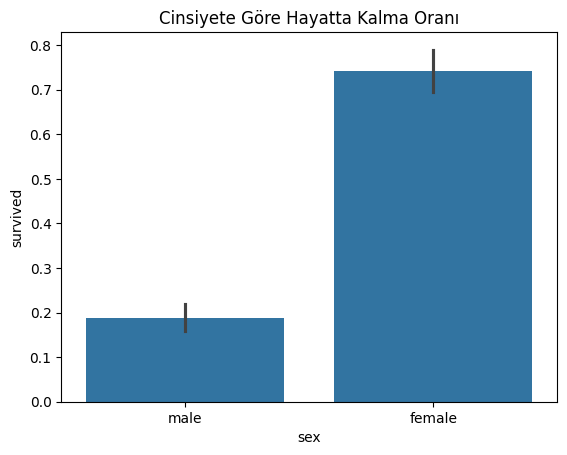

In [16]:
import matplotlib.pyplot as plt

sns.barplot(data=df, x="sex", y="survived")
plt.title("Cinsiyete Göre Hayatta Kalma Oranı")
plt.show()

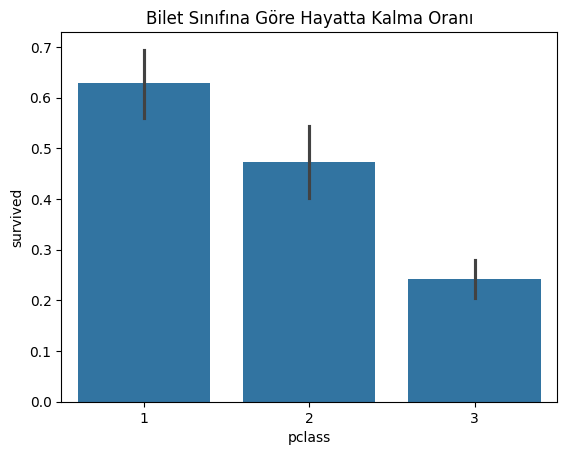

In [17]:
sns.barplot(data=df, x="pclass", y="survived")
plt.title("Bilet Sınıfına Göre Hayatta Kalma Oranı")
plt.show()

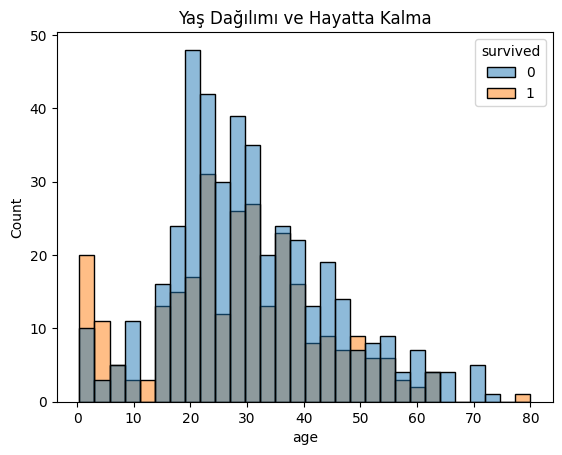

In [18]:
sns.histplot(data=df, x="age", hue="survived", bins=30)
plt.title("Yaş Dağılımı ve Hayatta Kalma")
plt.show()

In [19]:
#Gereksiz sütunları çıkarma
df_clean = df.drop(columns=["deck", "alive", "class", "who",
                            "adult_male", "embark_town", "alone"])
df_clean.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [20]:
#Eksik değerleri doldurma
df_clean["age"] = df_clean["age"].fillna(df_clean["age"].median())
df_clean["embarked"] = df_clean["embarked"].fillna(df_clean["embarked"].mode()[0])

df_clean.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,0
sibsp,0
parch,0
fare,0
embarked,0


In [21]:
#Metinleri sayıya çevirme
df_clean["sex"] = df_clean["sex"].map({"male": 0, "female": 1})
df_clean = pd.get_dummies(df_clean, columns=["embarked"], drop_first=True, dtype=int)

df_clean.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked_Q,embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1
